# PASO 1 (STEP 1)

In [24]:
import pandas as pd
import numpy as np
from scipy import stats as st
import matplotlib.pyplot as plt


In [ ]:
df_games = pd.read_csv("../data/games.csv")
df_games.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


# PASO 2 (STEP 2)

In [26]:
df_games.columns = df_games.columns.str.lower()
print(f" new columns {df_games.columns}")


 new columns Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'], dtype='object')


In [27]:
# Conversión de tipos
df_games.head()
df_games['year_of_release'] = df_games['year_of_release'].astype('Int64')
df_games['user_score'] = pd.to_numeric(df_games['user_score'], errors='coerce')


**Descripción de la conversión de tipos de datos:**

*Año de lanzamiento (year_of_release):* Se convierte a un tipo de dato entero (Int64) en lugar de un objeto de fecha (datetime). Esto evita la asignación de días y meses artificiales (como el 1 de enero) que introducirían ruido irrelevante para el análisis temporal.

*Puntuación de usuarios (user_score):* Se transforma a un formato numérico (float) en lugar de mantenerse como cadena de texto (object). Esto previene errores de interpretación y permite realizar cálculos estadísticos y agregaciones matemáticas de forma correcta.

**Description of Data Type Conversions:**

*Release Year (year_of_release):* Converted to an integer type (Int64) rather than a datetime object. This prevents the assignment of arbitrary days and months (such as January 1st) that would introduce irrelevant noise into temporal analysis.

*User Score (user_score):* Cast to a numeric format (float) instead of being left as a string (object). This prevents string-based interpretation errors and enables accurate statistical calculations and mathematical aggregations.

In [28]:
nulls_by_column = df_games.isna().sum()
print("**************** Data before nan cleaning ****************")
print(nulls_by_column)
print("**************** Data after nan cleaning ****************")
df_games = df_games.dropna(subset=['name', 'genre'])
print(df_games.isna().sum())

Games_without_critics = df_games[df_games['critic_score'].isna()]

nan_by_year = Games_without_critics.groupby('year_of_release')['name'].count()

regional_sales_nan = Games_without_critics.groupby('year_of_release')[['na_sales', 'eu_sales', 'jp_sales']].sum()

print("--- Ammount of games without critics per year ---")
print(nan_by_year)

print("\n--- Regional sales of games withput critics by year ---")
print(regional_sales_nan)

#Se convierten a NaN los TBD
df_games['user_score'] = pd.to_numeric(df_games['user_score'], errors='coerce')

**************** Data before nan cleaning ****************
name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         9125
rating             6766
dtype: int64
**************** Data after nan cleaning ****************
name                  0
platform              0
year_of_release     269
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8576
user_score         9123
rating             6764
dtype: int64
--- Ammount of games without critics per year ---
year_of_release
1980      9
1981     46
1982     36
1983     17
1984     14
1985     13
1986     21
1987     16
1988     14
1989     17
1990     16
1991     41
1992     42
1993     60
1994    120
1995    219
1996    255
1997    272
1998    351
1999    299
2000    207
2001    156


#### Tratamiento y Origen de Valores Ausentes

**¿Por qué se eliminaron ciertos valores y se conservaron otros?**
* **Eliminación de registros críticos (`name` y `genre`):** Tras realizar el conteo de valores nulos (`NaN`), se identificaron únicamente 2 registros sin nombre y 2 sin género. Al representar menos del **0.03%** del volumen total (16,715 registros), su eliminación es estadísticamente despreciable y no afecta la integridad del análisis.
* **Conservación de valores nulos (`critic_score`, `user_score` y `rating`):** Se decidió mantener los `NaN` en las columnas de calificación y clasificación sin aplicar imputación. Extrapolar medidas de tendencia central (media o mediana) sobre métricas subjetivas distorsionaría la variabilidad real del mercado, mezclando artificialmente obras maestras con títulos de menor impacto comercial. Para análisis posteriores de correlación o segmentación, se aplicarán filtros específicos utilizando únicamente los registros válidos.

**¿A qué se deben los valores ausentes?**
* **Errores de ingesta:** La ausencia puntual de valores en `name` y `genre` sugiere omisiones aisladas durante el registro o consolidación histórica de la base de datos.
* **Valores `TBD` (*To Be Determined*):** Corresponden a títulos que aún no alcanzaban el umbral mínimo de reseñas de usuarios para generar un puntaje consolidado. Para facilitar el procesamiento matemático, se transformaron a `NaN` mediante coerción numérica (`float`).
* **Contexto de la industria:** Desde una perspectiva de dominio respaldada por **5 años de experiencia profesional en la industria de los videojuegos**, la alta proporción de títulos sin puntaje de crítica coincide directamente con los picos de expansión y producción masiva del sector (evidenciados en el volumen anual de lanzamientos). Durante estos auges comerciales, una gran cantidad de juegos de nicho, bajo presupuesto o lanzamientos regionales pasaron desapercibidos tanto para la prensa especializada como para el público masivo.



#### Missing Values Handling & Root Cause Analysis

**Why were certain values dropped while others were preserved?**
* **Dropping critical records (`name` and `genre`):** A missing value audit revealed only 2 records lacking a `name` and 2 lacking a `genre`. Representing less than **0.03%** of the entire dataset (16,715 records), dropping these rows is statistically negligible and preserves overall data integrity.
* **Preserving null values (`critic_score`, `user_score`, and `rating`):** Missing entries in scoring and ESRB rating columns were intentionally left as `NaN` without imputation. Extrapolating central tendency metrics (mean or median) onto subjective review scores would distort true market variance by artificially averaging critically acclaimed masterpieces with minor releases. For subsequent correlation or segmentation analyses, specific filters will be applied to isolate valid records.

**What are the probable causes of these missing values?**
* **Data ingestion errors:** Isolated nulls in `name` and `genre` point to minor logging omissions when compiling or merging historical database records.
* **`TBD` (*To Be Determined*) entries:** Represent titles that had not yet reached the minimum threshold of user reviews required to compute a public score. To enable mathematical computations, these strings were coerced into `NaN` values (`float`).
* **Industry context:** Drawing from **5 years of professional experience in the video game industry**, the high volume of unreviewed titles aligns directly with periods of rapid market expansion and mass production (as reflected in annual release trends). During these commercial booms, numerous niche, low-budget, or region-locked titles went unnoticed by both specialized press and mainstream players.

In [29]:
#Cálculo de ventas totales para cada videojuego
df_games["total_sales"] = df_games["na_sales"] + df_games["jp_sales"] + df_games["eu_sales"] + df_games["other_sales"]
df_games.head()


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,31.38


# PASO 3 (STEP 3)

year_of_release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      60
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: name, dtype: int64


Text(0, 0.5, 'Ammount of games released')

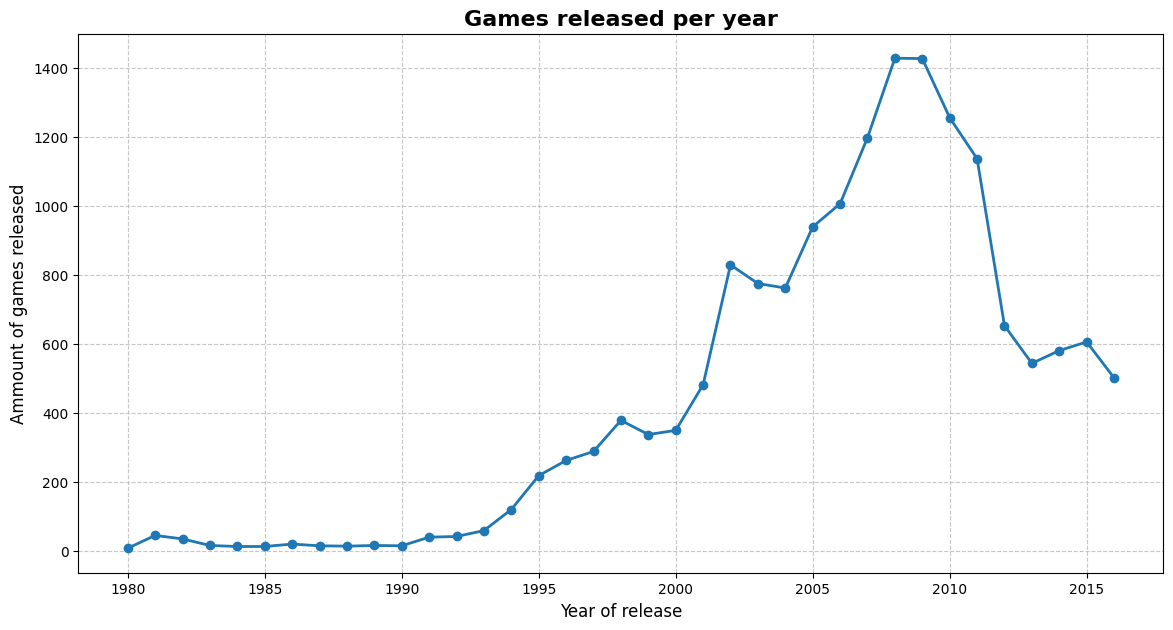

In [30]:
games_released_per_year = df_games.groupby("year_of_release")["name"].count()
print(games_released_per_year)

plt.figure(figsize=(14, 7))

plt.plot(games_released_per_year.index, 
         games_released_per_year.values, 
         marker='o',       
         linewidth=2,      
         linestyle='-')

plt.grid(True, linestyle='--', alpha=0.7)

plt.title('Games released per year', fontsize=16, fontweight='bold')
plt.xlabel('Year of release', fontsize=12)
plt.ylabel('Ammount of games released', fontsize=12)


#### Evolución Histórica de Lanzamientos y Hitos de la Industria

La evolución temporal del volumen de lanzamientos refleja directamente los hitos tecnológicos y cambios estructurales en el mercado de los videojuegos:
* **1991 (Primer punto de inflexión):** Se observa el primer incremento significativo en la producción de títulos, impulsado por el lanzamiento comercial de la **Super Nintendo (SNES)**.
* **1994 – 2000 (Expansión de la era de 32 bits y consolas domésticas):** La llegada de la **Sony PlayStation (PS1)** en 1994 genera un salto acelerado en el volumen de desarrollo, consolidando una curva de crecimiento sostenido que recibe un nuevo impulso en el año **2000** con el debut histórico de la **PlayStation 2 (PS2)**.
* **2006 (Pico y superación de la barrera de los 1,000 títulos):** La industria supera por primera vez la marca de los 1,000 juegos anuales, apalancada por la masificación y el impacto comercial de la **Nintendo Wii**.
* **Contracción posterior:** La caída observada en los registros subsiguientes responde a una transformación profunda en el ecosistema de consumo: la migración de jugadores hacia plataformas móviles (*smartphones*), la adopción masiva del modelo de negocio *Free-to-Play* (que prioriza actualizaciones continuas sobre catálogos masivos en formato físico) y los periodos de transición a la espera de las consolas de siguiente generación.


#### Historical Release Trends & Industry Milestones

The temporal evolution of game release volume directly mirrors major technological milestones and structural shifts within the industry:
* **1991 (First Inflection Point):** Marks the initial major surge in title production, coinciding with the commercial launch of the **Super Nintendo (SNES)**.
* **1994 – 2000 (Console Era Expansion):** The debut of the **Sony PlayStation (PS1)** in 1994 triggered a sharp upward shift in development volume, establishing a steady growth curve that received a fresh catalyst in **2000** with the launch of the **PlayStation 2 (PS2)**.
* **2006 (The 1,000-Title Milestone):** Annual production crossed the 1,000-game threshold for the first time, propelled by the massive commercial success and cultural penetration of the **Nintendo Wii**.
* **Subsequent Contraction:** The downward trend in later years reflects a profound transformation in player behavior and industry models: the migration of casual gamers toward mobile platforms (*smartphones*), the rise of the *Free-to-Play* business model (favoring live-service updates over traditional standalone releases), and the transition periods waiting for next-generation hardware.

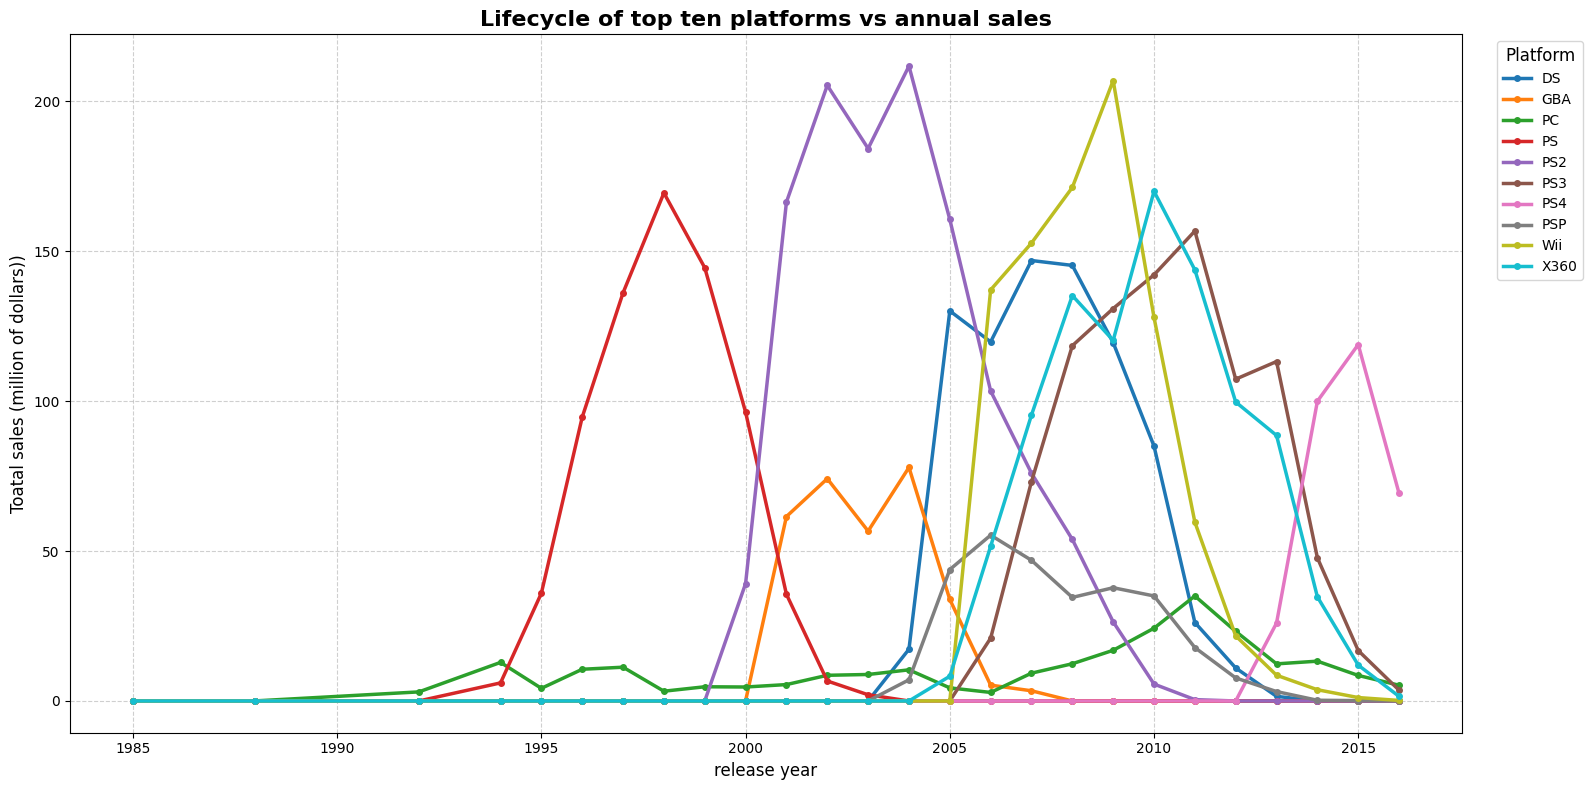

In [31]:

platforms_sales = df_games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
top_platforms = platforms_sales.iloc[:10]


top_10_platforms = top_platforms.index

df_top10 = df_games[df_games['platform'].isin(top_10_platforms)]

sales_distribution = df_top10.pivot_table(
    index='year_of_release', 
    columns='platform', 
    values='total_sales', 
    aggfunc='sum'
)

sales_distribution = sales_distribution.fillna(0)

plt.figure(figsize=(16, 8))

for platform in sales_distribution.columns:
    plt.plot(sales_distribution.index, 
             sales_distribution[platform], 
             label=platform, 
             linewidth=2.5, 
             marker='o',
             markersize=4)

plt.grid(True, linestyle='--', alpha=0.6)
plt.title('Lifecycle of top ten platforms vs annual sales', fontsize=16, fontweight='bold')
plt.xlabel('release year', fontsize=12)
plt.ylabel('Toatal sales (million of dollars))', fontsize=12)

plt.legend(title='Platform', title_fontsize='12', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()


In [32]:
lifespans = df_top10.groupby('platform')['year_of_release'].agg(['min', 'max'])

lifespans['lifecycle_years'] = lifespans['max'] - lifespans['min'] + 1

print(lifespans.sort_values(by='lifecycle_years', ascending=False))

average_lifespan = lifespans['lifecycle_years'].mean()
print(f"\n average lifecycle is {average_lifespan:.1f} years.")

           min   max  lifecycle_years
platform                             
PC        1985  2016               32
DS        1985  2013               29
PS2       2000  2011               12
PSP       2004  2015               12
X360      2005  2016               12
PS3       2006  2016               11
Wii       2006  2016               11
PS        1994  2003               10
GBA       2000  2007                8
PS4       2013  2016                4

 average lifecycle is 14.1 years.


#### Ciclo de Vida de las Plataformas y Dinámicas de Mercado

El análisis temporal revela patrones clave sobre la longevidad y el rendimiento comercial de las distintas plataformas:
* **Correlación entre éxito, catálogo y ventas:** El ciclo de vida de una consola está fuertemente vinculado a su éxito comercial, impulsado por su rendimiento técnico (*performance*) y su jugabilidad. Un mejor desempeño atrae a un mayor número de desarrolladores, ampliando el catálogo de juegos y acelerando, a su vez, el volumen de ventas.
* **La atemporalidad del PC:** A diferencia de las consolas con ciclos de vida definidos, el PC abarca toda la ventana temporal analizada al tratarse de una plataforma intrínsecamente atemporal. Su capacidad para albergar títulos de múltiples generaciones de consolas le otorga una permanencia continua, aunque con un nivel de ventas unitarias menor en comparación con las consolas líderes, al menos hasta 2016.
* **Longevidad y retrasos generacionales (PS3 y Xbox 360):** Consolas como la **PlayStation 3** y la **Xbox 360** muestran una presencia sostenida y prolongada a lo largo del tiempo. Esta estabilidad no responde únicamente a sus cifras de ventas acumuladas (que en algunos casos fueron superadas), sino a los retrasos experimentados en el lanzamiento de la siguiente generación de consolas (PS4 y Xbox One), lo que extendió artificialmente su vigencia comercial en el mercado.


#### Platform Lifecycles & Market Dynamics

The temporal analysis reveals key patterns regarding the longevity and commercial performance of different platforms:
* **Correlation between success, library size, and sales:** A console's lifecycle is closely tied to its commercial success, driven by hardware performance and playability. Higher appeal attracts more developers, significantly expanding the game catalog and consequently boosting sales volume.
* **The timeless nature of PC:** Unlike consoles with finite lifecycles, the PC spans the entire temporal window as an inherently timeless platform. Its capability to run titles across multiple console generations ensures continuous presence, albeit with lower unit sales compared to leading consoles, at least through 2016.
* **Longevity and generational delays (PS3 & Xbox 360):** Consoles such as the **PlayStation 3** and **Xbox 360** exhibit extended, sustained market presence over time. This durability was driven not solely by their total sales figures (which were occasionally surpassed), but by delays in the rollout of next-generation hardware (PS4 and Xbox One), which effectively prolonged their commercial relevance.

In [33]:
df_actual = df_games[df_games['year_of_release'] >= 2014].copy()

print(f"filter dataset has {df_actual.shape[0]} rows.")

filter dataset has 1689 rows.


Tomamos solo los datos a partir del 2014 debido a que a finales del 2013 salieron el ps4 y el xbox one, lo cual hace que tengamos datos actuales de la nueva generación.

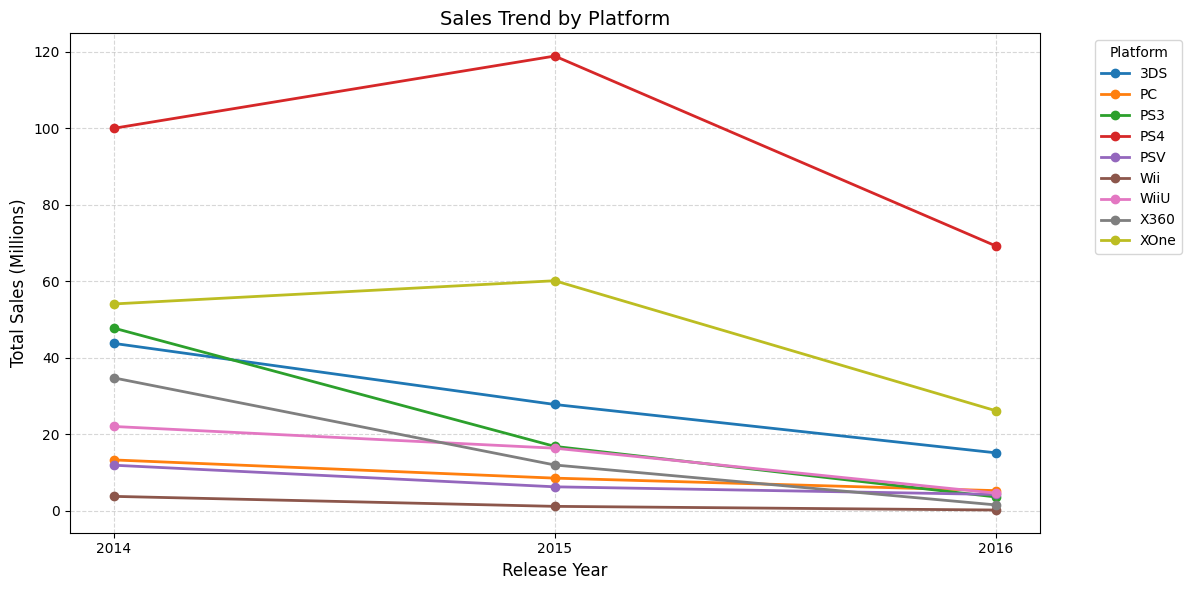

In [34]:
top_platforms = df_actual.groupby("platform")["total_sales"].sum().nlargest(9).index

plt.figure(figsize=(12, 6))

pivot_line = (
    df_actual[df_actual["platform"].isin(top_platforms)]
    .pivot_table(
        index="year_of_release",
        columns="platform",
        values="total_sales",
        aggfunc="sum",
    )
    .fillna(0)
)

for platform in pivot_line.columns:
    plt.plot(
        pivot_line.index,
        pivot_line[platform],
        marker="o",
        linewidth=2,
        label=platform,
    )

#graphic
years_list = [str(int(x)) for x in pivot_line.index]

plt.xticks(ticks=pivot_line.index, labels=years_list)

plt.title("Sales Trend by Platform", fontsize=14)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Total Sales (Millions)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Platform", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


#### Plataformas Líderes, Impacto Portátil y Proyección de Rentabilidad

* **Plataformas dominantes:** Las consolas líderes en ventas para esta ventana temporal son **PS4** y **Xbox One**, seguidas por **PS3**, **Xbox 360** y **Nintendo 3DS**, las cuales ya mostraban un comportamiento a la baja al encontrarse en la fase final de sus respectivos ciclos de vida.
* **Afectación de las consolas portátiles:** Dispositivos portátiles como la **Nintendo 3DS** y la **PS Vita** sufrieron una fuerte depreciación comercial debido a la irrupción y masificación de los *smartphones*.
* **Hipótesis sobre la caída de ventas (2015 – 2016):** El descenso generalizado en las ventas registrado entre 2015 y 2016 podría explicarse por la ausencia de datos completos hasta diciembre (mes clave con picos históricos de ventas para esta industria). No obstante, esta hipótesis no puede comprobarse estadísticamente, ya que el conjunto de datos cuenta únicamente con el año de lanzamiento/registro y carece de marcas temporales mensuales.
* **Oportunidades de rentabilidad:** Las plataformas con mayor potencial de rentabilidad en este contexto temporal eran **PS4** y **Xbox One**, dado que se encontraban en las etapas iniciales de sus ciclos de vida comerciales.

#### Leading Platforms, Handheld Impact & Profitability Outlook

* **Dominant platforms:** The leading consoles in sales for this time window were the **PS4** and **Xbox One**, followed by the **PS3**, **Xbox 360**, and **Nintendo 3DS**, which were already on a downward trend as they approached the end of their lifecycles.
* **Impact on handheld consoles:** Portable devices such as the **Nintendo 3DS** and **PS Vita** were negatively impacted and depreciated due to the rise and widespread adoption of *smartphones*.
* **Hypothesis on the 2015–2016 sales drop:** The widespread decline in sales observed from 2015 through 2016 could stem from the lack of data through December—historically the peak month for entertainment hardware sales. However, this cannot be empirically proven since the dataset only provides yearly records rather than monthly timestamps.
* **Profitable opportunities:** The platforms with the highest profit potential in this context were the **PS4** and **Xbox One**, as they were entering the early stages of their commercial lifecycles at the time.

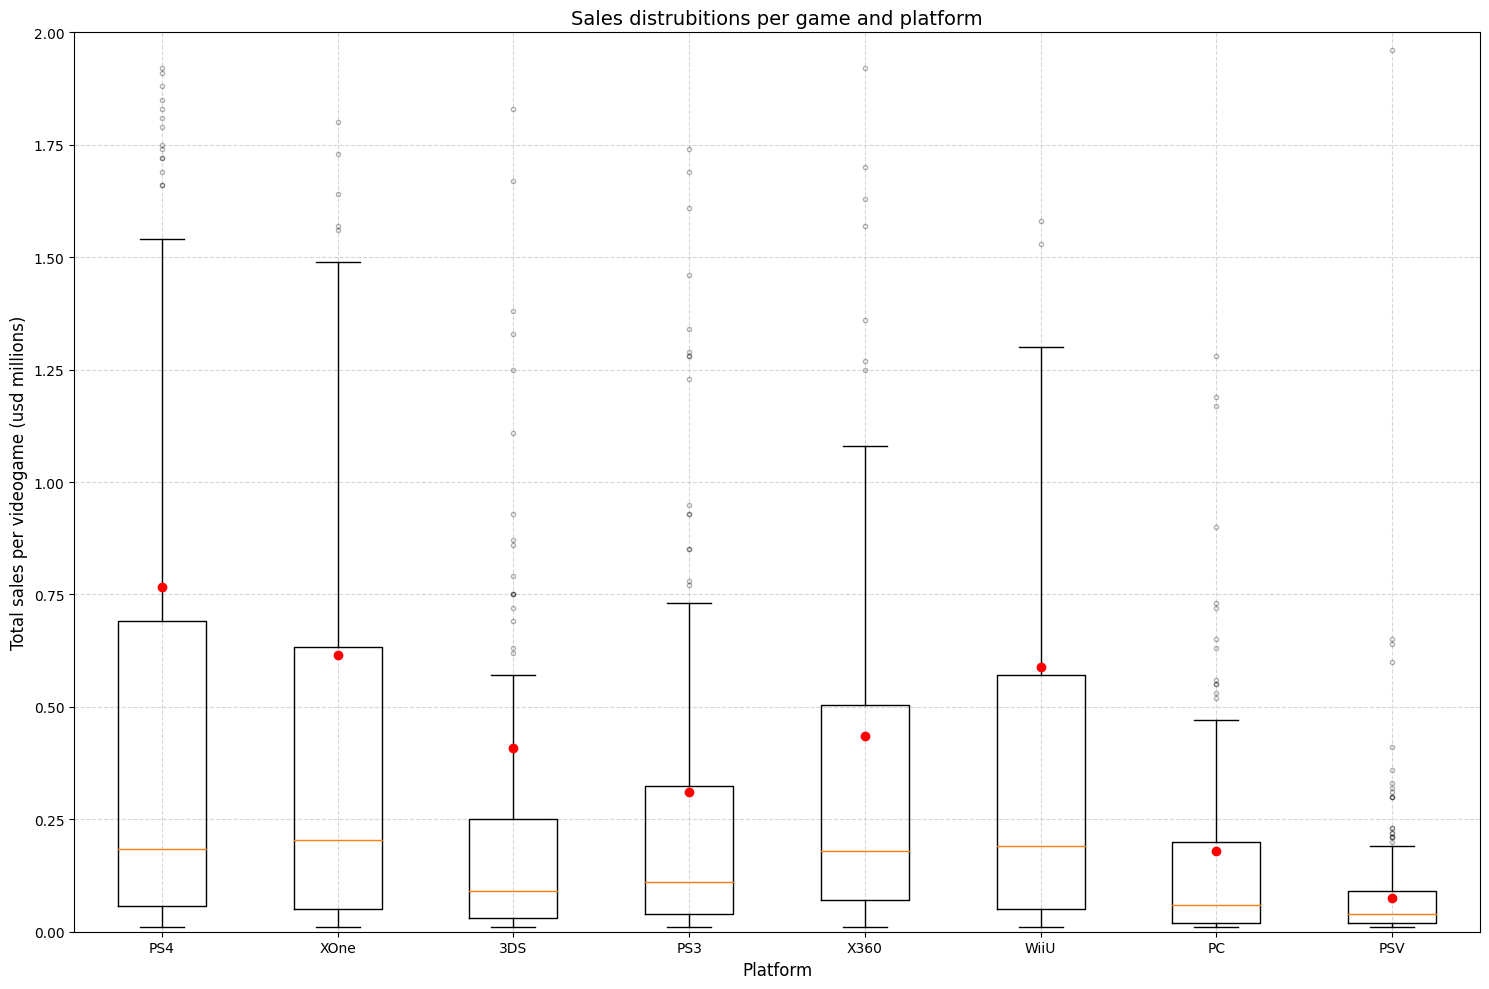

In [35]:
top_platforms = (
    df_actual.groupby("platform")["total_sales"].sum().nlargest(8).index
)
df_top = df_actual[df_actual["platform"].isin(top_platforms)]

data_to_plot = [
    df_top[df_top["platform"] == plat]["total_sales"].dropna()
    for plat in top_platforms
]

plt.figure(figsize=(15, 10))


plt.boxplot(
    data_to_plot,
    labels=top_platforms,
    showmeans=True,
    showfliers=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
    },
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.3},
)

plt.title("Sales distrubitions per game and platform", fontsize=14)
plt.xlabel("Platform", fontsize=12)
plt.ylabel("Total sales per videogame (usd millions)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.ylim(0, 2.0)

plt.tight_layout()
plt.show()

#### Análisis de Distribución de Ventas y Dispersión (Boxplots)

* **Análisis de la mediana:** Se observa claramente que cuatro de las siete plataformas evaluadas registran una mediana cercana a los \$250,000 USD. Esta métrica ofrece una perspectiva realista y robusta sobre el rendimiento del 50% central de los títulos de cada catálogo.
* **Plataformas de menor rendimiento central:** En el caso de PS3 y PC, los valores se sitúan por debajo de los \$100,000 USD, mientras que para Nintendo 3DS y PS Vita son aún más bajos. Esto se explica, para las consolas portátiles, por la sustitución gradual frente a los *smartphones*, y para la PS3, por el declive natural en la producción de nuevos títulos.
* **Sesgo a la derecha y comparación Media vs. Mediana:** Dado que no todos los juegos son éxitos masivos, la media aritmética dista considerablemente de la mediana en la mayoría de las plataformas, evidenciando un marcado **sesgo hacia la derecha**. Debido a que el promedio se infla artificialmente por títulos con ventas millonarias, la media pierde validez general; por ello, la **mediana** se posiciona como el indicador adecuado para analizar el comportamiento central de las ventas.
* **Comportamiento compacto (PS Vita):** En plataformas como PS Vita, el cuerpo del diagrama (que representa el rango intercuartílico con el 50% de la muestra) muestra una alta compresión, lo que indica que la gran mayoría de sus títulos registran cifras de ventas muy similares y acotadas.
* **Presencia de valores atípicos (*Outliers*):** La abundancia de *outliers* superiores responde a títulos insignia que marcaron a toda una generación y/o pertenecen a franquicias consolidadas de alto impacto comercial.


#### Sales Distribution Analysis & Dispersion (Boxplots)

* **Median analysis:** Four out of the seven evaluated platforms exhibit a median close to \$250,000 USD. This metric provides a realistic and robust benchmark indicating where the middle 50% of game sales stand.
* **Lower-tier central performance:** For PS3 and PC, values fall below \$100,000 USD, while Nintendo 3DS and PS Vita record even lower figures. For handheld consoles, this reflects gradual displacement by smartphones; for the PS3, it aligns with the natural decline in catalog production.
* **Right-skewness and Mean vs. Median:** Because not every game is a blockbuster, the arithmetic mean diverges significantly from the median across most platforms, revealing a strong **right skew**. Since the average is artificially inflated by multi-million-selling titles, the mean loses reliability; therefore, the **median** serves as the proper metric to analyze central sales behavior.
* **Compact behavior (PS Vita):** In platforms like the PS Vita, the box body (representing the interquartile range with 50% of the sample) is heavily compressed, indicating that the vast majority of its titles sell very similar, modest quantities.
* **Presence of Outliers:** The high frequency of upper outliers is driven by generation-defining flagship titles and established multi-million-dollar franchises.

In [36]:
games_comparison = df_actual.pivot_table(
    index="name",
    columns="platform",
    values="total_sales",
    aggfunc="sum",
)

multiplatform_games = games_comparison.dropna(thresh=2)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print(multiplatform_games)

platform                                             3DS    PC   PS3    PS4   PSP   PSV   Wii  WiiU  X360  XOne
name                                                                                                           
2014 FIFA World Cup Brazil                           NaN   NaN  0.61    NaN   NaN   NaN   NaN   NaN  0.43   NaN
3rd Super Robot Wars Z Jigoku Hen                    NaN   NaN  0.23    NaN   NaN  0.19   NaN   NaN   NaN   NaN
3rd Super Robot Wars Z: Tengoku-Hen                  NaN   NaN  0.15    NaN   NaN  0.19   NaN   NaN   NaN   NaN
7 Days to Die                                        NaN   NaN   NaN   0.14   NaN   NaN   NaN   NaN   NaN  0.05
Adventure Time: Finn & Jake Investigations          0.09   NaN  0.08   0.10   NaN   NaN   NaN  0.05  0.09  0.05
Adventure Time: The Secret of the Nameless          0.01   NaN   NaN    NaN   NaN   NaN   NaN   NaN  0.01   NaN
Adventure Time: The Secret of the Nameless Kingdom  0.07   NaN   NaN    NaN   NaN   NaN   NaN   NaN  0.0

#### Dinámica de Franquicias Exitosas y Canibalización Generacional

* **Efecto de franquicias consolidadas:** Los títulos pertenecientes a franquicias de alto éxito comercial experimentan ventas notablemente superiores en las consolas de nueva generación, lo que genera una **canibalización** directa sobre las ventas de su generación predecesora.
* **Casos de estudio representativos:** Este comportamiento se evidencia de forma clara en franquicias de gran tracción como *Far Cry*, *Call of Duty: Black Ops III* y los títulos deportivos de 2K (por ejemplo, la saga *WWE*), entre otros.
* **Comportamiento en títulos de menor impacto:** En contraste, aquellos juegos con una repercusión o perfil comercial más modesto replican este patrón de migración hacia la nueva plataforma, pero con una brecha o diferencia de ventas mucho más estrecha y menos drástica entre ambas generaciones de consolas.


#### Successful Franchise Dynamics & Generational Cannibalization

* **Established franchise effect:** Titles belonging to highly successful commercial franchises achieve significantly higher sales on the newest console generation, directly **cannibalizing** sales on the preceding hardware generation.
* **Representative case studies:** This pattern is clearly evidenced in major franchises such as *Far Cry*, *Call of Duty: Black Ops III*, and 2K sports titles (e.g., the *WWE* series), among others.
* **Behavior of lower-impact titles:** Conversely, games with a more modest market profile follow this same generational migration pattern, though with a much narrower and less dramatic sales margin between console generations.

In [37]:
genre_analysis = (
    df_actual.groupby("genre")["total_sales"]
    .agg(["sum", "mean", "median", "count"])
    .sort_values(by="sum", ascending=False)
)

print(genre_analysis)

                 sum      mean  median  count
genre                                        
Action        199.36  0.322068   0.090    619
Shooter       170.94  1.335469   0.515    128
Sports        109.48  0.680000   0.180    161
Role-Playing  101.44  0.459005   0.110    221
Misc           37.55  0.332301   0.090    113
Fighting       28.22  0.470333   0.125     60
Racing         27.52  0.398841   0.090     69
Platform       18.09  0.476053   0.140     38
Adventure      17.55  0.094865   0.030    185
Simulation     13.13  0.298409   0.100     44
Strategy        3.96  0.107027   0.060     37
Puzzle          2.21  0.157857   0.045     14


#### Dominio del Género de Acción y Factores de Éxito Comercial

* **El liderazgo del género de acción:** No resulta una sorpresa que el género de acción encabece las preferencias del mercado, ya que exige del jugador una coordinación inmediata para afrontar desafíos dinámicos. Casos emblemáticos como el estreno de *God of War* en PS4 marcaron hitos históricos en volumen de ventas.
* **El atractivo de los *shooters* y la conectividad:** Los juegos de disparos destacan por su componente multijugador *online*, ofreciendo partidas en mapas compactos que proporcionan diversión instantánea. Esta filosofía de red impulsa a una gran cantidad de usuarios a adquirir el título para formar parte de dicha comunidad de entretenimiento.
* **La lógica de los títulos deportivos:** Las entregas deportivas replican un comportamiento comercial análogo, impulsadas por la competitividad y la interacción social.
* **Contrastes con categorías de menor tracción:** Si bien existen géneros en categorías inferiores que también implementan opciones multijugador, su enfoque principal suele gravitar hacia experiencias de un solo jugador (*single-player*) o carecen de un ecosistema en red robusto, lo que limita la velocidad y la magnitud de su masificación en el mercado.


#### Action Genre Dominance & Commercial Success Factors

* **The leadership of the action genre:** It comes as no surprise that the action genre leads market preferences, as it demands immediate coordination from the player to face dynamic challenges. Landmark releases such as *God of War* on the PS4 achieved historic sales milestones.
* **The appeal of shooters and online connectivity:** Shooters stand out for their online multiplayer component, delivering instant fun through matches on compact maps. This networked philosophy drives a large number of users to purchase titles just to join the entertainment network.
* **The logic of sports titles:** Sports games follow a similar commercial logic, driven by competitiveness and social interaction.
* **Contrast with lower-traction categories:** Although some lower-tier categories also implement multiplayer options, their primary focus tends to gravitate toward single-player experiences or lack a robust networked ecosystem, limiting the speed and scale of their market penetration.

--- Correlation Matrix PS4 ---
              total_sales  critic_score  user_score
total_sales      1.000000      0.401903   -0.043186
critic_score     0.401903      1.000000    0.546434
user_score      -0.043186      0.546434    1.000000


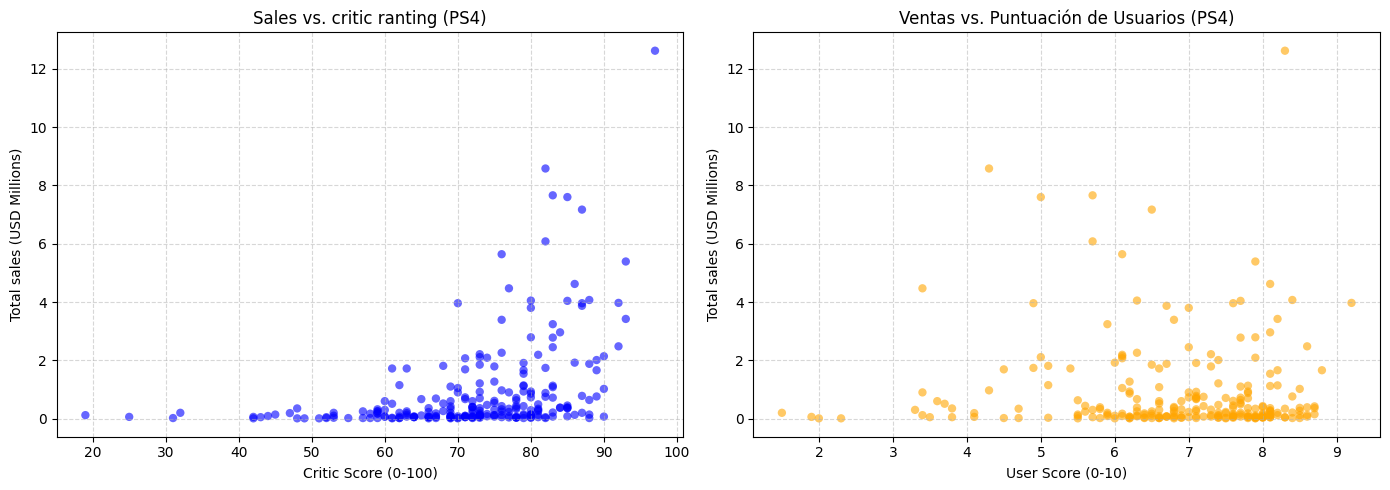

In [47]:
# PS$ is selected as the relevant platform to analise the correlation
platform_name = "PS4"
df_platform = df_actual[df_actual["platform"] == platform_name].dropna(
    subset=["critic_score", "user_score"]
)

corr_matrix = df_platform[
    ["total_sales", "critic_score", "user_score"]
].corr()

print(f"--- Correlation Matrix {platform_name} ---")
print(corr_matrix)

# Scatter Graphics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    df_platform["critic_score"],
    df_platform["total_sales"],
    alpha=0.6,
    color="blue",
    edgecolors="none",
)
axes[0].set_title(f"Sales vs. critic ranting ({platform_name})")
axes[0].set_xlabel("Critic Score (0-100)")
axes[0].set_ylabel("Total sales (USD Millions)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Gráfico 2: Ventas vs User Score
axes[1].scatter(
    df_platform["user_score"],
    df_platform["total_sales"],
    alpha=0.6,
    color="orange",
    edgecolors="none",
)
axes[1].set_title(f"Ventas vs. Puntuación de Usuarios ({platform_name})")
axes[1].set_xlabel("User Score (0-10)")
axes[1].set_ylabel("Total sales (USD Millions)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### Análisis de Correlación: Ventas y Calificaciones en PS4

* **Ventas vs. Puntaje de la Crítica ($r = 0.4019$):** Se observa una correlación positiva moderada. A medida que mejora la valoración de la prensa especializada, las ventas del título tienden a incrementarse. Si bien no representa una relación lineal perfecta, existe una influencia comercial evidente.
* **Ventas vs. Puntaje de los Usuarios ($r = -0.0431$):** El coeficiente es prácticamente nulo (ligeramente negativo), lo que demuestra la ausencia de una relación lineal entre la calificación otorgada por los jugadores en PS4 y su volumen de ventas. Un título puede registrar puntuaciones bajas por parte de la comunidad y aun así alcanzar ventas millonarias, o viceversa.
* **Puntaje de la Crítica vs. Puntaje de los Usuarios ($r = 0.5464$):** Existe una correlación positiva de moderada a alta entre ambas métricas. Por lo general, la crítica especializada y los jugadores coinciden en su criterio sobre la calidad de un título; como hipótesis secundaria, aunque menos frecuente, la percepción de los usuarios podría verse influenciada por el consenso previo de la crítica.

---

#### Correlation Analysis: Sales & Review Scores on PS4

* **Sales vs. Critic Score ($r = 0.4019$):** A moderate positive correlation is observed. Higher ratings from specialized critics generally align with stronger game sales. While not a strictly linear relationship, the commercial impact is evident.
* **Sales vs. User Score ($r = -0.0431$):** The coefficient is virtually zero (slightly negative), indicating no linear relationship between player ratings on PS4 and unit sales. A title can receive low user scores and still sell millions of copies, or vice versa.
* **Critic Score vs. User Score ($r = 0.5464$):** There is a moderate-to-strong positive correlation between both rating groups. Overall, critics and players tend to align on game quality; as a secondary, less common hypothesis, user perception may occasionally be influenced by prior critical consensus.

# PASO 4 (Step 4)

In [38]:
df_games.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 16713 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16713 non-null  object 
 2   year_of_release  16444 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16713 non-null  float64
 5   eu_sales         16713 non-null  float64
 6   jp_sales         16713 non-null  float64
 7   other_sales      16713 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           9949 non-null   object 
 11  total_sales      16713 non-null  float64
dtypes: Int64(1), float64(7), object(4)
memory usage: 1.7+ MB


In [39]:

for region in ["na_sales", "eu_sales", "jp_sales"]:
  print(f"--- Top 5 Plataforms in {region} ---")
  top_plat = df_actual.groupby("platform")[region].sum().nlargest(5)
  print(top_plat)
  print("\n")


--- Top 5 Plataforms in na_sales ---
platform
PS4     98.61
XOne    81.27
X360    28.30
3DS     22.64
PS3     22.05
Name: na_sales, dtype: float64


--- Top 5 Plataforms in eu_sales ---
platform
PS4     130.04
XOne     46.25
PS3      25.54
PC       17.97
3DS      16.12
Name: eu_sales, dtype: float64


--- Top 5 Plataforms in jp_sales ---
platform
3DS     44.24
PS4     15.02
PSV     14.54
PS3     11.22
WiiU     7.31
Name: jp_sales, dtype: float64




#### Comportamiento Atípico y Preferencias del Mercado Japonés

* **Dominio de consolas portátiles:** A diferencia de los mercados de Europa y Norteamérica, Japón posiciona en la cima de ventas a dos plataformas portátiles: la **Nintendo 3DS** y la **PlayStation Vita**. Esto responde directamente a un estilo de vida urbano y dinámico caracterizado por los largos desplazamientos diarios en transporte público, donde la portabilidad resulta un factor determinante.
* **La ausencia de Xbox y el perfil de la oferta:** Aunque a nivel global la PS4 y la Xbox One lideran las listas, en Japón la consola de Microsoft está ausente, lo que evidencia que su propuesta de hardware y catálogo no sintonizan con las preferencias culturales y de género del consumidor nipón. Del mismo modo, la aparición de la **Nintendo Wii U** refuerza este comportamiento de mercado marcadamente diferenciado.
* **Identidad nacional y adaptación al estilo de vida:** La alta aceptación de estas plataformas se fundamenta en una fuerte afinidad por la manufactura nacional (marcas locales como Nintendo y Sony) y en catálogos diseñados en torno a franquicias y estilos de juego muy arraigados en la cultura local (como los JRPGs y experiencias multijugador presenciales), consolidando un ecosistema de entretenimiento único en el mundo.

---

#### Atypical Behavior & Japanese Market Preferences

* **Handheld Dominance:** Unlike the European and North American markets, Japan places two portable consoles at the top of sales: the **Nintendo 3DS** and the **PlayStation Vita**. This directly reflects an urban, fast-paced lifestyle characterized by long daily commutes via public transit, where portability is a decisive factor.
* **Xbox Absence & Catalog Alignment:** Although globally the PS4 and Xbox One lead the charts, the Xbox One is conspicuously absent in Japan, highlighting that its hardware proposition and game library do not resonate with local cultural and genre preferences. Likewise, the appearance of the **Nintendo Wii U** reinforces this distinctly unique market behavior.
* **National Identity & Lifestyle Fit:** The strong adoption of these platforms is driven by a deep-rooted affinity for domestic manufacturing (local brands like Nintendo and Sony) and software libraries tailored to franchises and gameplay styles beloved in the region (such as JRPGs and localized multiplayer experiences), consolidating an entertainment ecosystem unlike anywhere else in the world.

In [40]:
for region in ["na_sales", "eu_sales", "jp_sales"]:
  print(f"--- Top 5 Plataforms in {region} ---")
  top_plat = df_actual.groupby("genre")[region].sum().nlargest(5)
  print(top_plat)
  print("\n")


--- Top 5 Plataforms in na_sales ---
genre
Shooter         79.02
Action          72.53
Sports          46.13
Role-Playing    33.47
Misc            15.05
Name: na_sales, dtype: float64


--- Top 5 Plataforms in eu_sales ---
genre
Action          74.68
Shooter         65.52
Sports          45.73
Role-Playing    28.17
Racing          14.13
Name: eu_sales, dtype: float64


--- Top 5 Plataforms in jp_sales ---
genre
Role-Playing    31.16
Action          29.58
Fighting         6.37
Misc             5.61
Shooter          4.87
Name: jp_sales, dtype: float64




#### Diferencias Culturales y Preferencias de Género por Región

* **Validación de la hipótesis del mercado japonés:** El análisis por género confirma el comportamiento atípico de Japón. Franquicias insignia asociadas históricamente al catálogo de Xbox (como *Call of Duty*, *Battlefield* o *Halo*) pertenecen al género de disparos (*Shooters*), el cual apenas ocupa la quinta posición en las preferencias del público nipón.
* **Homogeneidad en mercados occidentales (Norteamérica y Europa):** Tanto en Norteamérica como en Europa, los géneros de **Acción**, **Deportes** y ***Shooters*** conforman de manera consistente el podio de los tres más vendidos, alternando posiciones entre sí. En contraste, los juegos de rol (*Role-Playing* / RPG) ocupan el cuarto lugar en ambas regiones.
* **El liderazgo del RPG en Japón:** En el mercado japonés, el género de *Role-Playing* se posiciona en el primer lugar indiscutible. Esta inversión en las preferencias demuestra que los hábitos de consumo y entretenimiento en Japón responden a raíces culturales profundamente distintas a las de Occidente, priorizando la narrativa, el desarrollo de personajes y el juego portátil sobre la acción competitiva en línea.

---

#### Cultural Differences & Genre Preferences by Region

* **Validation of the Japanese market hypothesis:** Genre distribution confirms Japan's atypical market behavior. Flagship franchises historically tied to the Xbox ecosystem (such as *Call of Duty*, *Battlefield*, and *Halo*) belong to the *Shooter* genre, which ranks only fifth in Japanese consumer preferences.
* **Homogeneity in Western markets (North America & Europe):** Across both North America and Europe, **Action**, **Sports**, and **Shooters** consistently make up the top three best-selling genres, alternating positions at the top. Conversely, *Role-Playing* games (RPGs) sit in fourth place in both regions.
* **RPG leadership in Japan:** In Japan, the *Role-Playing* genre claims the undisputed number one spot. This sharp contrast in preferences proves that gaming habits in Japan are shaped by deeply rooted cultural factors distinct from Western markets, prioritizing narrative depth, character progression, and portable play over fast-paced online competitive action.

In [41]:
df_actual["rating"] = df_actual["rating"].fillna("Unclasified")

esrb_regional = (
    df_actual.groupby("rating")[["na_sales", "eu_sales", "jp_sales"]]
    .sum()
    .sort_values(by="na_sales", ascending=False)
)

print(esrb_regional)

             na_sales  eu_sales  jp_sales
rating                                   
M               96.42     93.44      8.01
Unclasified     64.72     58.95     56.90
E               50.74     58.06      8.94
T               38.95     34.07     14.78
E10+            33.23     26.16      4.46


#### Clasificación ESRB, Regiones y Títulos sin Clasificar (*Rating*)

* **Presencia de títulos sin clasificar y diversidad de sistemas:** La existencia de un volumen considerable de juegos sin clasificar dentro del conjunto de datos suele explicarse por la utilización de sistemas de clasificación regional externos a Norteamérica, tales como **PEGI** en Europa o **CERO** en Japón, los cuales no siempre se mapean de forma directa con los estándares de la ESRB.
* **Dominio de la clasificación M (*Mature*):** La categoría **M (Mature)** encabeza claramente las ventas globales. Este liderazgo guarda total coherencia con el comportamiento de los mercados norteamericano y europeo, donde géneros de alta tracción comercial como la **acción** y los ***shooters*** dominan las listas de preferencia.
* **Correlación demográfica y comercial:** El éxito comercial de los títulos clasificados como *Mature* refleja cómo las franquicias dirigidas a audiencias maduras y adultas impulsan el volumen principal de ventas en Occidente, alineando las restricciones de edad con los géneros más lucrativos de la industria.

---

#### ESRB Ratings, Regions, and Unrated Titles

* **Unrated titles and regional rating systems:** The presence of a significant volume of unrated games in the dataset is largely due to the use of regional rating systems outside North America—such as **PEGI** in Europe and **CERO** in Japan—which do not always directly map to ESRB standards.
* **Dominance of the M (*Mature*) Rating:** The **M (Mature)** category clearly leads global sales. This supremacy aligns perfectly with consumer behavior in North America and Europe, where high-commercial-traction genres like **action** and **shooters** dominate purchasing preferences.
* **Demographic and commercial correlation:** The commercial success of titles rated *Mature* highlights how franchises targeted at mature and adult audiences drive the core sales volume in Western markets, perfectly aligning age restrictions with the industry's most lucrative genres.

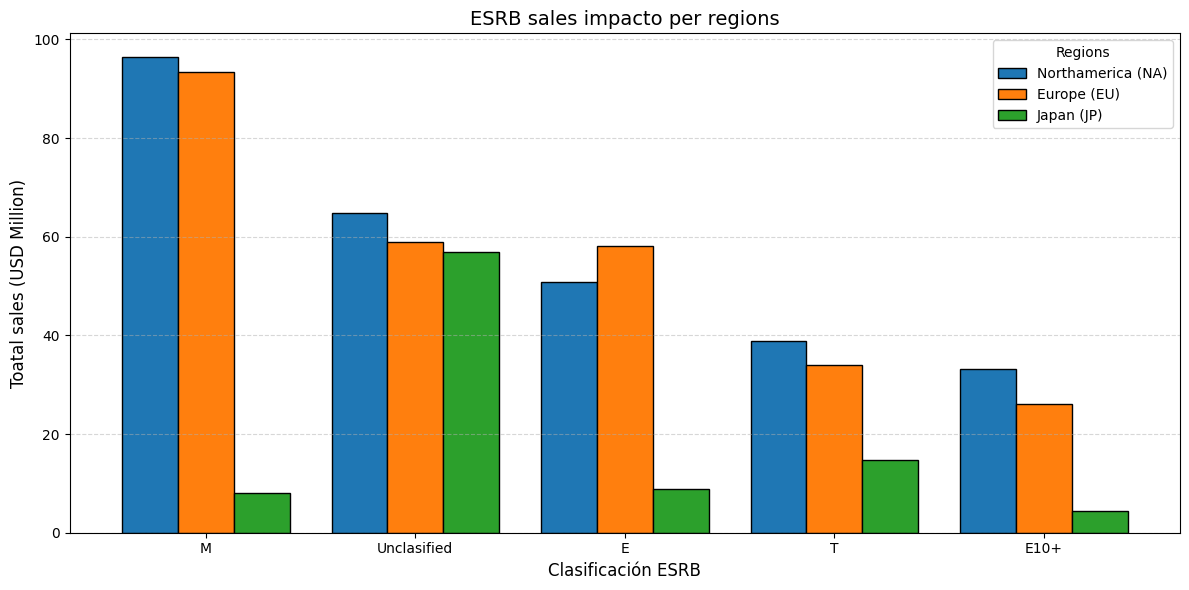

In [42]:
# Crear el gráfico de barras
ax = esrb_regional.plot(
    kind="bar", figsize=(12, 6), width=0.8, edgecolor="black"
)

plt.title(
    "ESRB sales impacto per regions", fontsize=14
)
plt.xlabel("Clasificación ESRB", fontsize=12)
plt.ylabel("Toatal sales (USD Million)", fontsize=12)
plt.xticks(rotation=0)  # Mantiene las etiquetas horizontales
plt.legend(
    ["Northamerica (NA)", "Europe (EU)", "Japan (JP)"], title="Regions"
)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### Distribución de Clasificaciones ESRB y Sistemas Regionales

* **Liderazgo occidental en categorías *Mature* (M) y *Everyone* (E):** Se evidencia claramente que Norteamérica y Europa constituyen los principales mercados consumidores tanto de títulos clasificados como **M (*Mature*)** —impulsados por el alto volumen comercial de *shooters* y juegos de acción— como de títulos familiares bajo la clasificación **E (*Everyone*)**.
* **Impacto de los sistemas de clasificación locales en los valores ausentes:** Existe una proporción considerable de juegos sin clasificación ESRB asignada en el conjunto de datos. Un alto porcentaje de estos registros proviene de Europa y Japón, regiones que operan bajo sus propios organismos reguladores (**PEGI** y **CERO**, respectivamente) y cuyas etiquetas no siempre se homologan directamente dentro de los registros basados en el estándar norteamericano.

---

#### ESRB Rating Distribution & Regional Classification Systems

* **Western dominance in *Mature* (M) and *Everyone* (E) categories:** North America and Europe clearly stand out as the primary consumer markets for both **M (*Mature*)** titles—driven by the strong commercial performance of shooters and action games—and family-oriented games rated **E (*Everyone*)**.
* **Impact of regional rating boards on unrated records:** A substantial share of titles in the dataset lack an assigned ESRB rating. A large proportion of these unrated entries originate from Europe and Japan, regions governed by their own regulatory boards (**PEGI** and **CERO**, respectively) whose classifications do not always map directly into North American-centric datasets.

# PASO 5 (Step 5)

#### Pruebas de Hipótesis Estadísticas: Configuración y Prueba 1 (Xbox One vs. PC)

Para validar científicamente las diferencias observadas en las métricas del conjunto de datos, se establece un nivel de significancia ($\alpha$) del **0.05** para las pruebas estadísticas.

* **Definición del marco de prueba (Prueba 1):**
  * **Hipótesis Nula ($H_0$):** Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son iguales ($\mu_{\text{XOne}} = \mu_{\text{PC}}$).
  * **Hipótesis Alternativa ($H_1$):** Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son diferentes ($\mu_{\text{XOne}} \neq \mu_{\text{PC}}$).
* **Justificación metodológica:** Al tratarse de dos muestras independientes y requerir la comparación de sus medias, se emplea la prueba **t de Student para muestras independientes** (`ttest_ind` de SciPy). Esta prueba evalúa si la diferencia observada entre las dos medias es estadísticamente significativa o si puede atribuirse a la variabilidad aleatoria del muestreo.

---

#### Statistical Hypothesis Testing: Setup and Test 1 (Xbox One vs. PC)

To scientifically validate the differences observed in the dataset metrics, a significance level ($\alpha$) of **0.05** is established for the statistical tests.

* **Test Framework Definition (Test 1):**
  * **Null Hypothesis ($H_0$):** The average user ratings for the Xbox One and PC platforms are equal ($\mu_{\text{XOne}} = \mu_{\text{PC}}$).
  * **Alternative Hypothesis ($H_1$):** The average user ratings for the Xbox One and PC platforms are different ($\mu_{\text{XOne}} \neq \mu_{\text{PC}}$).
* **Methodological Justification:** Dealing with two independent samples and requiring a comparison of their means, the **independent samples t-test** (`ttest_ind` from SciPy) is utilized. This test evaluates whether the observed difference between the two means is statistically significant or merely attributable to random sampling variability.

In [43]:
alpha = 0.05

df_ratings = df_actual.dropna(subset=["user_score"])

ratings_xone = df_ratings[df_ratings["platform"] == "XOne"]["user_score"]
ratings_pc = df_ratings[df_ratings["platform"] == "PC"]["user_score"]

stat_h1, p_value_h1 = st.ttest_ind(ratings_xone, ratings_pc, equal_var=False)

print(f"Estadístico t: {stat_h1:.4f}")
print(f"P-value: {p_value_h1:.4f}")

if p_value_h1 < alpha:
    print(
        "Conclussion: Rechazamos H0. Las calificaciones promedio son estadísticamente diferentes.\n"
    )
else:
    print(
        "Conclusión: No podemos rechazar H0. No hay evidencia suficiente para afirmar que son diferentes.\n"
    )

Estadístico t: 1.5778
P-value: 0.1160
Conclusión: No podemos rechazar H0. No hay evidencia suficiente para afirmar que son diferentes.



#### Resultados e Interpretación de la Prueba 1 (Xbox One vs. PC)

* **Evaluación del valor $p$ y la hipótesis nula:** Dado que el valor $p$ obtenido es mayor que el nivel de significancia ($\alpha = 0.05$), **no se rechaza la hipótesis nula ($H_0$)**. Esto indica que no existe evidencia estadística suficiente para afirmar que las calificaciones promedio de los usuarios difieran entre ambas plataformas; por lo tanto, se concluye que las calificaciones promedio de los usuarios para Xbox One y PC son estadísticamente iguales.
* **Consistencia con el estadístico de prueba:** Este comportamiento se ve respaldado por el estadístico, el cual muestra que los promedios de ambas muestras no presentan una separación marcada, reflejando una paridad empírica en la valoración otorgada por los usuarios en ambos entornos.

---

#### Test 1 Results & Interpretation (Xbox One vs. PC)

* **$p$-value evaluation and the null hypothesis:** Since the obtained $p$-value is greater than the significance level ($\alpha = 0.05$), **we fail to reject the null hypothesis ($H_0$)**. This indicates that there is insufficient statistical evidence to claim that the average user ratings differ between the two platforms; therefore, we conclude that the average user ratings for Xbox One and PC are statistically equivalent.
* **Consistency with the test statistic:** This outcome is supported by the test statistic, which shows that the means of both samples are not widely separated, reflecting an empirical parity in user ratings across both environments.

#### Pruebas de Hipótesis Estadísticas: Prueba 2 (Acción vs. Deportes)

* **Definición del marco de prueba (Prueba 2):**
  * **Hipótesis Nula ($H_0$):** Las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son iguales ($\mu_{\text{Action}} = \mu_{\text{Sports}}$).
  * **Hipótesis Alternativa ($H_1$):** Las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son diferentes ($\mu_{\text{Action}} \neq \mu_{\text{Sports}}$).
* **Justificación metodológica:** Nuevamente se emplea la **prueba t de Student para muestras independientes** (bilateral) (`ttest_ind` de SciPy). Los datos se filtran previamente a partir de la columna de géneros para aislar las submuestras correspondientes, permitiendo evaluar si la diferencia entre las medias muestrales de ambos géneros es estadísticamente significativa o producto del azar.

---

#### Statistical Hypothesis Testing: Test 2 (Action vs. Sports)

* **Test Framework Definition (Test 2):**
  * **Null Hypothesis ($H_0$):** The average user ratings for the Action and Sports genres are equal ($\mu_{\text{Action}} = \mu_{\text{Sports}}$).
  * **Alternative Hypothesis ($H_1$):** The average user ratings for the Action and Sports genres are different ($\mu_{\text{Action}} \neq \mu_{\text{Sports}}$).
* **Methodological Justification:** Once again, the **independent samples t-test** (two-tailed) (`ttest_ind` from SciPy) is utilized. The dataset is filtered by the genre column to isolate the respective sub-samples, allowing us to evaluate whether the difference between the sample means of both genres is statistically significant or merely due to random sampling variability.

In [44]:
ratings_action = df_ratings[df_ratings["genre"] == "Action"]["user_score"]
ratings_sports = df_ratings[df_ratings["genre"] == "Sports"]["user_score"]

stat_h2, p_value_h2 = st.ttest_ind(
    ratings_action, ratings_sports, equal_var=False
)

print(f"Estadístico t: {stat_h2:.4f}")
print(f"P-value: {p_value_h2:.4f}")

if p_value_h2 < alpha:
    print(
        "Conclusión: Rechazamos H0. Las calificaciones promedio son estadísticamente diferentes."
    )
else:
    print(
        "Conclusión: No podemos rechazar H0. No hay evidencia suficiente para afirmar que son diferentes."
    )

Estadístico t: 8.3846
P-value: 0.0000
Conclusión: Rechazamos H0. Las calificaciones promedio son estadísticamente diferentes.


#### Resultados e Interpretación de la Prueba 2 (Acción vs. Deportes)

* **Evaluación del valor $p$ y la hipótesis nula:** Al obtener un valor $p$ sustancialmente menor que el nivel de significancia ($\alpha = 0.05$), **se rechaza la hipótesis nula ($H_0$)**. Esto demuestra que existen pruebas estadísticas suficientes para afirmar que las calificaciones promedio de los usuarios entre el género de acción y el de deportes son estadísticamente diferentes.
* **Consistencia con el estadístico de prueba:** La magnitud del estadístico refleja que las medias muestrales de ambos géneros presentan una separación considerable, respaldando de manera categórica la decisión de rechazar la igualdad entre ambos grupos.

---

#### Test 2 Results & Interpretation (Action vs. Sports)

* **$p$-value evaluation and the null hypothesis:** Given a $p$-value substantially lower than the significance level ($\alpha = 0.05$), **the null hypothesis ($H_0$) is rejected**. This demonstrates that there is sufficient statistical evidence to conclude that the average user ratings between the Action and Sports genres are statistically different.
* **Consistency with the test statistic:** The magnitude of the test statistic indicates that the sample means of both genres are widely separated, categorically reinforcing the decision to reject the assumption of equality between the two groups.

# PASO 6 (Step 6)

#### Conclusiones y Hallazgos Principales del Análisis Exploratorio (EDA)

* **Transición tecnológica y recambio generacional:** El volumen de ventas de videojuegos está fuertemente condicionado por el ciclo de vida y la adopción de nuevas generaciones de hardware, evidenciando una migración comercial directa hacia las plataformas más recientes.
* **Influencia cultural y regional:** Los hábitos de consumo varían de forma drástica según la región geoeconómica, reflejándose en particularidades de mercado muy marcadas, tal como se comprobó en el comportamiento de Japón.
* **Asimetría de ventas y robustez estadística:** La distribución de las ventas presenta un marcado sesgo a la derecha impulsado por escasos títulos de éxito masivo (*blockbusters*). Esto invalida a la media aritmética como métrica central fiable e impone el uso de la **mediana** como el indicador óptimo de tendencia central, respaldado por el análisis de diagramas de caja (*boxplots*).
* **Polarización de preferencias por mercado:** Mientras que Norteamérica y Europa priorizan los géneros de acción y *shooters* en consolas de sobremesa, Japón muestra una preferencia absoluta por los juegos de rol (RPG) y las plataformas portátiles.
* **Pruebas de hipótesis y variabilidad:** Las pruebas estadísticas confirman la existencia de diferencias significativas en las calificaciones de los usuarios al comparar géneros de videojuegos, a diferencia de la paridad observada al contrastar plataformas específicas (como Xbox One y PC).
* **Estrategia comercial y adopción de hardware:** Si bien existen mercados globales sólidos, la penetración de ciertas marcas (como Xbox en Japón) se ve severamente limitada por factores culturales y de arraigo hacia fabricantes locales (Sony y Nintendo).
* **Priorización de desarrollo:** La estrategia comercial y de desarrollo debe enfocar sus recursos prioritariamente en las consolas de última generación dentro de la ventana analizada (principalmente PS4 y Xbox One), por concentrar el mayor volumen de adopción del mercado.

---

#### Conclusions & Key Findings from the Exploratory Data Analysis (EDA)

* **Technological transition and generational turnover:** Video game sales volume is strongly driven by the hardware lifecycle and the adoption of new console generations, revealing a direct commercial migration toward newer platforms.
* **Cultural and regional influence:** Consumer habits vary drastically across geo-economic regions, reflected in distinct market particularities as demonstrated by the behavior of the Japanese market.
* **Sales asymmetry and statistical robustness:** The sales distribution exhibits a pronounced right-skew driven by a few massive blockbuster titles. This renders the arithmetic mean unreliable and establishes the **median** as the optimal central tendency metric, supported by boxplot dispersion analysis.
* **Market preference polarization:** While North America and Europe prioritize action games and shooters on home consoles, Japan displays an overwhelming preference for role-playing games (RPGs) and portable platforms.
* **Hypothesis testing and variability:** Statistical tests confirm significant differences in user ratings when comparing video game genres, contrasting with the parity observed when contrasting specific platforms (such as Xbox One and PC).
* **Commercial strategy and hardware adoption:** Although global markets remain robust, the penetration of certain brands (like Xbox in Japan) is severely constrained by cultural preferences and brand affinity favoring domestic manufacturers (Sony and Nintendo).
* **Development prioritization:** Commercial and development strategies should focus resources primarily on current-generation consoles within the analyzed timeframe (principally PS4 and Xbox One), as they concentrate the largest market adoption volume.